# Kidney Ultrasound — Exploratory Data Analysis (EDA)

**Environment:** Cursor / local Jupyter.<br> 
**Scope:** dataset inspection, descriptive statistics, annotation checks and data-quality review **only**. <br>
Model development and GPU training will be in separate Colab notebooks.

**Datasets:** `bbdd_kidney` (diagnosis images and annotations) and the Open Kidney Ultrasound files. <br>
The figures here describe the files actually present locally; published dataset counts are used only as cross-checks.

## 1. Setup and dataset paths
Run cells from top to bottom. The project root is found by searching upward from the notebook's working directory; no Colab-specific paths are needed.

We import the Python libraries needed for the analysis and define where our datasets are stored. This allows us to access the images, labels, and segmentation masks throughout the notebook.

In [14]:
from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import hashlib
import random
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root from the current Jupyter working directory.
root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "bbdd_kidney").is_dir()),
    None
)
if root is None:
    raise FileNotFoundError("Cannot find bbdd_kidney. Open the repository in Cursor and run this notebook there.")

images_dir = root / "bbdd_kidney" / "images"
labels_dir = root / "bbdd_kidney" / "labels"
masks_dir = root / "bbdd_kidney" / "masks"
open_kidney_dir = root / "kidneyUS_images_25_june_2025"
open_kidney_project_dir = root / "kidneyUS-main"

print("Project root:", root)
print("Classification image folder:", images_dir)
assert images_dir.is_dir() and labels_dir.is_dir() and masks_dir.is_dir()

Project root: /Users/noadori/Desktop/University/Year IV Semester I/Project-data-science
Classification image folder: /Users/noadori/Desktop/University/Year IV Semester I/Project-data-science/bbdd_kidney/images


## 2. Dataset inventory
### 2.1 File counts and formats
Count files recursively by extension, and distinguish the two dataset collections.

We examine the structure of our datasets and count the available files and their formats. We also check whether every ultrasound image has a corresponding annotation file and segmentation mask.

In [21]:
folders = {
    "Classification images": images_dir,
    "Classification labels": labels_dir,
    "Classification masks": masks_dir,
    "Open Kidney images": open_kidney_dir,
    "Open Kidney code/labels": open_kidney_project_dir,
}

inventory_rows = []
for name, folder in folders.items():
    if not folder.exists():
        print(f"{name}: folder missing — {folder}")
        continue
    files = [p for p in folder.rglob("*") if p.is_file() and not p.name.startswith(".")]
    counts = Counter(p.suffix.lower() or "[no extension]" for p in files)
    print(f"{name}: {len(files)} files | {dict(counts)}")
    for extension, count in sorted(counts.items()):
        inventory_rows.append({"dataset_folder": name, "extension": extension, "count": count})

inventory_df = pd.DataFrame(inventory_rows)
display(inventory_df)

Classification images: 1985 files | {'.jpg': 1985}
Classification labels: 1985 files | {'.txt': 1985}
Classification masks: 1985 files | {'.mat': 1985}
Open Kidney images: 536 files | {'.png': 534, '.csv': 2}
Open Kidney code/labels: 2175 files | {'.pdf': 1, '.txt': 1, '.md': 1, '.png': 2137, '.docx': 1, '.xlsx': 1, '[no extension]': 1, '.csv': 2, '.py': 30}


,dataset_folder,extension,count
0,Classification images,.jpg,1985
1,Classification labels,.txt,1985
2,Classification masks,.mat,1985
3,Open Kidney images,.csv,2
4,Open Kidney images,.png,534
5,Open Kidney code/labels,.csv,2
6,Open Kidney code/labels,.docx,1
7,Open Kidney code/labels,.md,1
8,Open Kidney code/labels,.pdf,1
9,Open Kidney code/labels,.png,2137


### 2.2 Filename consistency
The image, text-label and `.mat` mask files are expected to share their basename. This checks matching filenames, **not** whether the contents are valid.

In [22]:
image_files = sorted(images_dir.glob("*.jpg"))
label_files = sorted(labels_dir.glob("*.txt"))
mask_files = sorted(masks_dir.glob("*.mat"))

image_ids = {p.stem for p in image_files}
label_ids = {p.stem for p in label_files}
mask_ids = {p.stem for p in mask_files}

checks = {
    "JPG images": len(image_ids),
    "TXT annotations": len(label_ids),
    "MAT masks": len(mask_ids),
    "Images without TXT": len(image_ids - label_ids),
    "Images without MAT": len(image_ids - mask_ids),
    "TXT without image": len(label_ids - image_ids),
    "MAT without image": len(mask_ids - image_ids),
}
display(pd.DataFrame(checks.items(), columns=["check", "count"]))
if image_ids - label_ids:
    print("Example missing TXT:", sorted(image_ids - label_ids)[:10])

,check,count
0,JPG images,1985
1,TXT annotations,1985
2,MAT masks,1985
3,Images without TXT,0
4,Images without MAT,0
5,TXT without image,0
6,MAT without image,0


## 3. Annotation schema and label validation
### 3.1 Inspect example annotation files
Typical fields include *Global diagnosis*, *Global pathologies*, *View* and zero or more *Bounding box* entries.

We examine the annotation files to understand what information is available for each ultrasound image. This includes whether the kidney is healthy or pathological, the ultrasound view, and the locations of specific abnormalities.

In [23]:
def numeric_sort(path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem)

for path in sorted(label_files, key=numeric_sort)[:5]:
    print("\n" + "=" * 40 + f"\n{path.name}\n")
    print(path.read_text(encoding="utf-8", errors="replace")[:1500])


1.txt

Image filename: 1.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 326 196 48 32 5


2.txt

Image filename: 2.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 299 225 31 34 5


3.txt

Image filename: 3.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 226 194 106 76 5


4.txt

Image filename: 4.jpg
Global diagnosis: 1
Global pathologies: 1 0
View: 0


5.txt

Image filename: 5.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 408 186 94 77 1
Bounding box 2: 323 152 62 52 9



### 3.2 Parse all labels and flag malformed records

The published URI-CADS dataset describes 450 healthy and 1,535 pathological cases; the local `Global diagnosis` encoding is checked against these counts. We retain numeric bounding-box class codes until the precise class-ID mapping is documented.

In [24]:
records = []
boxes = []
parse_issues = []
for path in label_files:
    fields = {"image_id": path.stem, "filename": f"{path.stem}.jpg",
              "diagnosis": None, "view": None, "global_p1": None, "global_p2": None, "n_boxes": 0}
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        line = line.strip()
        try:
            if line.startswith("Image filename:"):
                fields["filename"] = line.split(":", 1)[1].strip()
            elif line.startswith("Global diagnosis:"):
                fields["diagnosis"] = int(line.split(":", 1)[1].strip())
            elif line.startswith("View:"):
                fields["view"] = int(line.split(":", 1)[1].strip())
            elif line.startswith("Global pathologies:"):
                vals = line.split(":", 1)[1].split()
                if len(vals) != 2: raise ValueError("Expected two global pathology indicators")
                fields["global_p1"], fields["global_p2"] = map(int, vals)
            elif line.startswith("Bounding box"):
                vals = line.split(":", 1)[1].split()
                if len(vals) != 5: raise ValueError("Expected x y width height class")
                x, y, w, h, cls = map(int, vals)
                boxes.append({"image_id": path.stem, "x": x, "y": y,
                              "width": w, "height": h, "class_id": cls})
                fields["n_boxes"] += 1
        except (ValueError, IndexError) as exc:
            parse_issues.append({"file": path.name, "line": line, "issue": str(exc)})
    records.append(fields)

annotations_df = pd.DataFrame(records)
boxes_df = pd.DataFrame(boxes, columns=["image_id", "x", "y", "width", "height", "class_id"])
print("Parsed annotations:", len(annotations_df), "| bounding boxes:", len(boxes_df))
print("Malformed lines:", len(parse_issues))
print("Missing values per column:")
display(annotations_df.isna().sum().to_frame("missing"))
print("File-name mismatches:", sum(annotations_df["filename"] != (annotations_df["image_id"] + ".jpg")))
if parse_issues: display(pd.DataFrame(parse_issues).head(10))
display(annotations_df.head())

Parsed annotations: 1985 | bounding boxes: 2478
Malformed lines: 0
Missing values per column:


,missing
image_id,0
filename,0
diagnosis,0
view,0
global_p1,0
global_p2,0
n_boxes,0


File-name mismatches: 0


,image_id,filename,diagnosis,view,global_p1,global_p2,n_boxes
0,1,1.jpg,1,0,0,0,1
1,10,10.jpg,1,0,1,0,0
2,100,100.jpg,1,0,0,0,2
3,1000,1000.jpg,1,0,0,0,4
4,1001,1001.jpg,1,0,1,1,2


## 4. Label distributions
### 4.1 Binary diagnosis, ultrasound views, global pathology pairs
`Global diagnosis: 0` corresponds to healthy and `1` to pathological in the supplied URI-CADS material. Code-to-view and pathology-indicator mappings should be confirmed against dataset documentation before giving them clinical names.

We analyze how frequently each diagnosis, ultrasound view, and pathology annotation appears in the dataset. This helps us identify class imbalances that could affect how well our classification model learns.

In [25]:
print("Diagnosis counts (0=healthy, 1=pathological):")
display(annotations_df["diagnosis"].value_counts(dropna=False).sort_index().to_frame("images"))
print("View code counts:")
display(annotations_df["view"].value_counts(dropna=False).sort_index().to_frame("images"))
print("Global pathology indicator pairs:")
annotations_df["global_pair"] = annotations_df.apply(
    lambda r: f"{int(r.global_p1)} {int(r.global_p2)}"
    if pd.notna(r.global_p1) and pd.notna(r.global_p2) else "missing", axis=1
)
display(annotations_df["global_pair"].value_counts().to_frame("images"))
print("Local boxes per class ID (regions, not images):")
display(boxes_df["class_id"].value_counts().sort_index().to_frame("boxes"))

assert annotations_df["diagnosis"].dropna().isin([0, 1]).all(), "Unexpected diagnosis code"
print("Published dataset cross-check: expected healthy=450, pathological=1535")

Diagnosis counts (0=healthy, 1=pathological):


,images
diagnosis,
0,450
1,1535


View code counts:


,images
view,
0,1842
1,143


Global pathology indicator pairs:


,images
global_pair,
0 0,1276
1 1,395
1 0,200
0 1,114


Local boxes per class ID (regions, not images):


,boxes
class_id,
1,110
2,1073
3,92
4,384
5,34
6,11
7,618
8,111
9,45


Published dataset cross-check: expected healthy=450, pathological=1535


### 4.2 Visualize label distributions

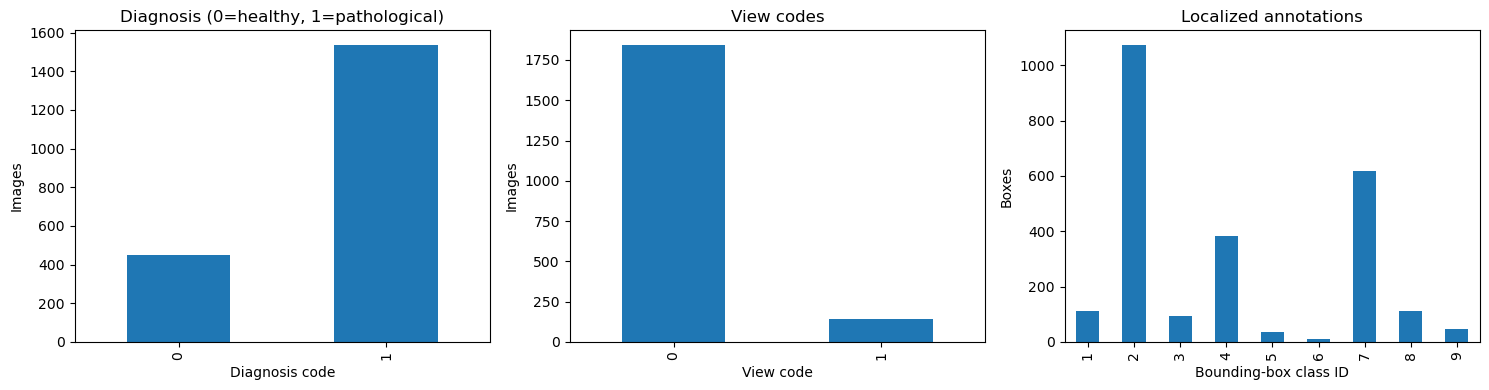

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
annotations_df["diagnosis"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Diagnosis (0=healthy, 1=pathological)", xlabel="Diagnosis code", ylabel="Images")
annotations_df["view"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="View codes", xlabel="View code", ylabel="Images")
boxes_df["class_id"].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set(title="Localized annotations", xlabel="Bounding-box class ID", ylabel="Boxes")
plt.tight_layout()
plt.show()

## 5. Image properties
### 5.1 Readability, dimensions, color mode, resolution and file size
These properties inform resizing, intensity preprocessing and potential acquisition-related confounding.

We examine the technical characteristics of the ultrasound images, including their dimensions, resolutions, color formats, and file sizes. This helps us understand how consistent the images are and what preprocessing may be necessary before training a CNN.

In [27]:
image_records = []
read_errors = []
for path in image_files:
    try:
        with Image.open(path) as im:
            im.load()
            image_records.append({"image_id": path.stem, "filename": path.name,
                                  "width": im.width, "height": im.height,
                                  "aspect_ratio": im.width / im.height,
                                  "mode": im.mode, "format": im.format,
                                  "size_kb": path.stat().st_size / 1024})
    except Exception as exc:
        read_errors.append({"filename": path.name, "error": str(exc)})
image_df = pd.DataFrame(image_records)
eda_df = image_df.merge(annotations_df, on=["image_id", "filename"], how="left", validate="one_to_one")
print("Readable images:", len(image_df), "Unreadable:", len(read_errors))
display(image_df[["width", "height", "aspect_ratio", "size_kb"]].describe().round(2))
print("Color modes:")
display(image_df["mode"].value_counts().to_frame("images"))
print("Most common resolutions:")
display(image_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_frame("images"))
if read_errors: display(pd.DataFrame(read_errors).head(10))

Readable images: 1985 Unreadable: 0


,width,height,aspect_ratio,size_kb
count,1985.00,1985.00,1985.00,1985.00
mean,789.13,552.11,1.43,40.53
std,31.56,24.88,0.03,4.49
min,382.00,375.00,0.88,25.58
25%,800.00,561.00,1.43,37.46
50%,800.00,561.00,1.43,40.46
75%,800.00,561.00,1.43,43.47
max,810.00,571.00,1.57,54.31


Color modes:


,images
mode,
RGB,1985


Most common resolutions:


images
width height        
800   561       1742
716   498        180
      459         48
382   436          1
383   435          1
731   466          1
728   508          1
727   504          1
724   509          1
707   508          1

### 5.2 Plot dimensions and class-conditional characteristics

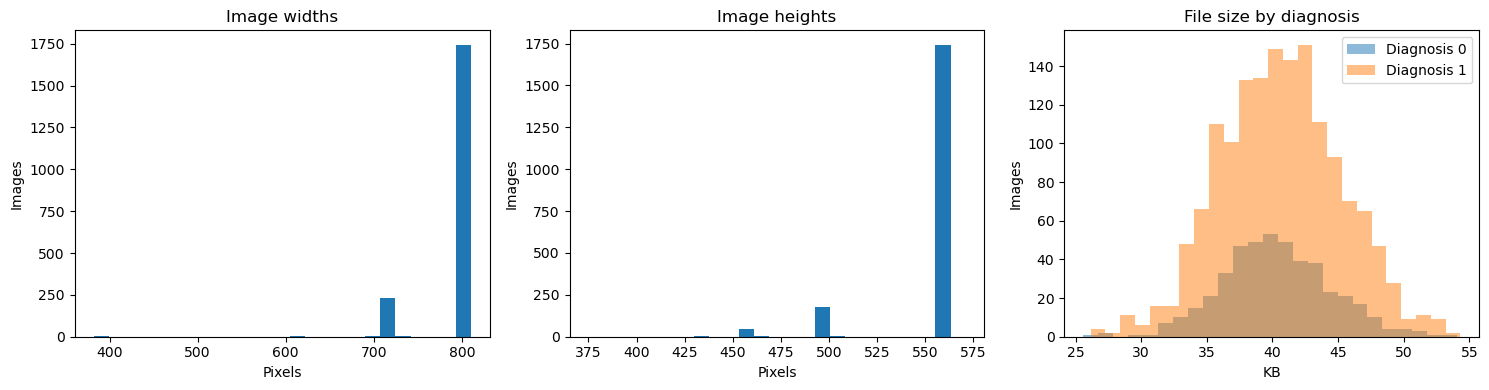

Image properties by diagnosis:


width                height               size_kb             
             mean median    std    mean median    std    mean median   std
diagnosis                                                                 
0          793.84  800.0  21.92  555.34  561.0  20.77   40.26  40.04  4.20
1          787.75  800.0  33.75  551.16  561.0  25.89   40.61  40.57  4.57

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(image_df["width"], bins=25)
axes[0].set(title="Image widths", xlabel="Pixels", ylabel="Images")
axes[1].hist(image_df["height"], bins=25)
axes[1].set(title="Image heights", xlabel="Pixels", ylabel="Images")
for code, group in eda_df.groupby("diagnosis"):
    axes[2].hist(group["size_kb"], bins=25, alpha=0.5, label=f"Diagnosis {code}")
axes[2].set(title="File size by diagnosis", xlabel="KB", ylabel="Images")
axes[2].legend()
plt.tight_layout()
plt.show()
print("Image properties by diagnosis:")
display(eda_df.groupby("diagnosis")[["width", "height", "size_kb"]].agg(["mean", "median", "std"]).round(2))

## 6. Representative image review
Display a small deterministic sample of images by diagnosis. **Do not interpret images as diagnoses yourself**; titles use the supplied annotations. Review for borders, overlays, poor visibility and artifacts. Avoid committing sensitive or identifiable visual outputs to a public repository.

We display examples of healthy and pathological kidney ultrasound images to visually explore the dataset. This allows us to observe differences in image appearance, quality, and anatomical structures.

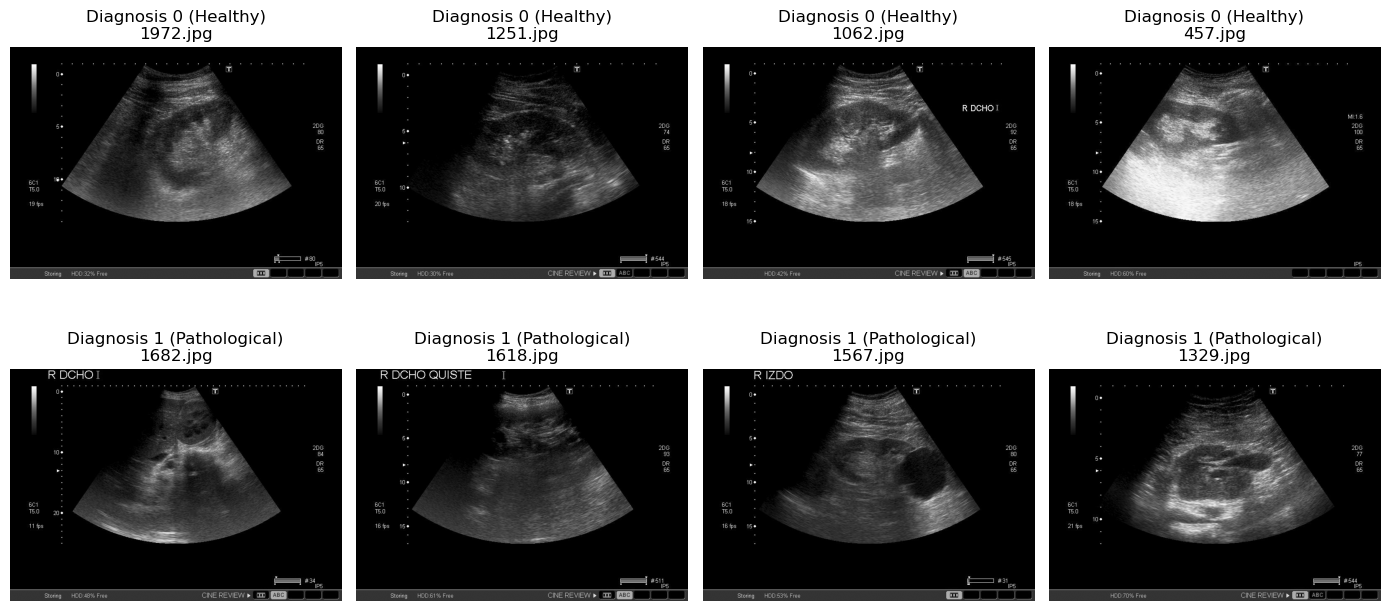

In [31]:

rng = random.Random(42)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

diagnosis_labels = {
    0: "Healthy",
    1: "Pathological"
}

for row, diagnosis in enumerate([0, 1]):
    choices = eda_df.loc[
        eda_df["diagnosis"] == diagnosis, "filename"
    ].tolist()

    selected = rng.sample(choices, k=min(4, len(choices)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected):
            with Image.open(images_dir / selected[col]) as im:
                ax.imshow(im.convert("L"), cmap="gray")

            ax.set_title(
                f"Diagnosis {diagnosis} ({diagnosis_labels[diagnosis]})\n"
                f"{selected[col]}"
            )

plt.tight_layout()
plt.show()


### 6.1 Visual Observations and Discussion

After examining four healthy (Diagnosis 0) and four pathological (Diagnosis 1) ultrasound images, we identified several characteristics relevant to our classification task.

**Main observations:**

- **Image appearance:** All eight images are displayed in grayscale and show differences in brightness, contrast, and visibility of anatomical structures.
- **Image quality:** Some images appear clearer than others, while certain areas contain noise, shadows, or reduced visibility.
- **Background and borders:** The images contain large black regions surrounding the ultrasound scan, as well as measurement scales and equipment information.
- **Text overlays:** Some images contain additional text, including anatomical descriptions and examination-related information. These overlays could introduce unwanted patterns into the CNN training process.
- **Healthy vs. pathological images:** The two groups show variations in kidney appearance, but visual differences are not always obvious. The classification labels are taken from the dataset annotations rather than determined through our own interpretation.

**Implications for preprocessing and CNN training:**

The images may benefit from consistent resizing and intensity normalization before training. We should also investigate whether text overlays, borders, and other non-anatomical information could influence model predictions.

However, cropping must be performed carefully to avoid removing important anatomical structures or surrounding clinical context.

**Limitations:**

This analysis is based on only eight randomly selected images and therefore cannot represent the full variability of the 1,985-image dataset. A more systematic assessment of image quality, artifacts, and potentially misleading visual features is needed.

**Potential dataset bias:** 

Some ultrasound images contain text annotations, measurement scales and equipment information. These non-anatomical features could influence CNN predictions and should be considered during future preprocessing and model evaluation. A systematic analysis of these overlays is outside the scope of this preliminary EDA.

**Conclusion:**

The visual inspection confirms that the dataset contains variability in image appearance and acquisition characteristics. These factors should be considered during preprocessing and model evaluation to reduce the risk of the CNN learning irrelevant image features instead of meaningful anatomical information.

## 7. Data quality and leakage risk
### 7.1 Exact duplicate file hashes
Hashing finds byte-for-byte identical JPGs, not visually similar or clinically duplicate images. Avoid interpreting the absence of exact duplicates as proof of patient independence.

We check for potential problems in the dataset, such as duplicate images, missing information, or inconsistent annotations. Identifying these issues is important to ensure that our future model is trained and evaluated using reliable data.

In [38]:
hash_groups = defaultdict(list)
for path in image_files:
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups[digest].append(path.name)
duplicate_groups = [names for names in hash_groups.values() if len(names) > 1]
print("Exact duplicate groups:", len(duplicate_groups))
print("Additional duplicate files:", sum(len(g) - 1 for g in duplicate_groups))
for group in duplicate_groups[:10]: print(group)

Exact duplicate groups: 0
Additional duplicate files: 0


### 7.2 Annotation consistency and limitations
Look for absent diagnoses, inconsistent healthy labels with pathology flags/boxes, invalid box sizes, and unverified patient identifiers. Some flags may require clinical verification; do not automatically relabel data.

In [39]:
print("Missing diagnosis values:", annotations_df["diagnosis"].isna().sum())
print("Unexpected diagnosis codes:", (~annotations_df["diagnosis"].isin([0, 1])).sum())
print("Nonpositive bounding box widths/heights:",
      ((boxes_df["width"] <= 0) | (boxes_df["height"] <= 0)).sum())
healthy = annotations_df[annotations_df["diagnosis"] == 0]
possible_conflicts = healthy[(healthy["n_boxes"] > 0) |
                             (healthy["global_p1"].fillna(0) != 0) |
                             (healthy["global_p2"].fillna(0) != 0)]
print("Healthy-labeled records with pathology indicators/boxes (inspect; don't relabel):", len(possible_conflicts))
print("Patient IDs: not established by the annotation schema inspected here.")
print("Do NOT assume random image-level train/test splits are patient-independent.")

Missing diagnosis values: 0
Unexpected diagnosis codes: 0
Nonpositive bounding box widths/heights: 0
Healthy-labeled records with pathology indicators/boxes (inspect; don't relabel): 0
Patient IDs: not established by the annotation schema inspected here.
Do NOT assume random image-level train/test splits are patient-independent.


Note: matching file hashes cannot detect visually similar images or different frames of the same examination. Patient-level independence must still be addressed before CNN evaluation.

## 8. Next Stage: CNN preparation

This section prepares the image filenames and diagnosis labels for future CNN training.<br>
Before CNN training, we need to verify whether the dataset includes reliable patient identifiers or an official split. Without that information, we cannot guarantee patient-independent evaluation.

In [42]:

# Export a simple classification manifest
output_dir = root / "results" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

manifest = annotations_df[["filename", "diagnosis"]].copy()

# Ensure only valid binary labels are exported
manifest = manifest[
    manifest["diagnosis"].isin([0, 1])
].copy()

manifest["diagnosis"] = manifest["diagnosis"].astype(int)

assert manifest["filename"].is_unique, "Duplicate filenames found"

assert manifest["filename"].apply(
    lambda filename: (images_dir / filename).is_file()
).all(), "Some images referenced by the manifest are missing"

manifest.to_csv(
    output_dir / "classification_manifest.csv",
    index=False
)

print("Classification manifest saved.")
print("Total samples:", len(manifest))


Classification manifest saved.
Total samples: 1985


## 9. EDA summary and handoff
We summarize the main findings of our preliminary analysis, including dataset composition, class distribution, image characteristics, and potential limitations. These results will guide our preprocessing decisions and the development of the first CNN classifier.

In [40]:
summary = {
    "classification_images": len(image_files),
    "annotation_files": len(label_files),
    "mask_files": len(mask_files),
    "readable_images": len(image_df),
    "unreadable_images": len(read_errors),
    "healthy_count": int((annotations_df["diagnosis"] == 0).sum()),
    "pathological_count": int((annotations_df["diagnosis"] == 1).sum()),
    "number_of_local_bounding_boxes": len(boxes_df),
    "unique_resolutions": image_df[["width", "height"]].drop_duplicates().shape[0],
    "exact_duplicate_groups": len(duplicate_groups),
    "annotation_parse_issues": len(parse_issues),
}
summary_df = pd.DataFrame(summary.items(), columns=["metric", "value"])
display(summary_df)

# Optional: enable to export aggregate table to your working copy.
# output_dir = root / "results" / "eda"
# output_dir.mkdir(parents=True, exist_ok=True)
# summary_df.to_csv(output_dir / "eda_summary.csv", index=False)

,metric,value
0,classification_images,1985
1,annotation_files,1985
2,mask_files,1985
3,readable_images,1985
4,unreadable_images,0
5,healthy_count,450
6,pathological_count,1535
7,number_of_local_bounding_boxes,2478
8,unique_resolutions,18
9,exact_duplicate_groups,0


### Findings to document

- **Confirmed:** main dataset has one JPG, TXT label and MAT mask per shared filename ID (subject to cell output); report any mismatch if found.
- **Confirmed after execution:** diagnosis distribution, image characteristics, annotation types, unreadable files and exact duplicates.
- **Caveats:** codes for view/pathology classes still require checking against the official annotation dictionary. A `Global pathologies: 0 0` entry does not necessarily mean healthy because localized findings may exist.
- **CNN readiness:** binary labels can be extracted, but first establish a valid patient/group-level separation where IDs are available, check licensing and avoid data leakage. **Training happens in another Colab notebook.**

**Next notebook (separate):** `02_basic_CNN.ipynb` for preprocessing, splitting, training and evaluation.